# Water Quality Classification Using Machine Learning

**Aim:** To classify a water sample as `safe` or `unsafe` using measured water-quality features.

This is a beginner-friendly classification project using one CSV dataset and five ML algorithms. **The dataset is synthetic educational sample data** and the predictions must not be used to decide whether real drinking water is safe.


## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC


## 2. Load the single CSV dataset
Upload `water_quality_dataset.csv` to the Colab Files panel before running this cell.

In [7]:
data = pd.read_csv('/content/water_quality_dataset.csv')
print(data.head())
print("\\nDataset shape:", data.shape)
print("\\nMissing values:\\n", data.isnull().sum())


         ph    hardness        solids  chloramines     sulfate  conductivity  \
0  6.168088  294.857482  15136.674911     5.035678  282.926360    302.934159   
1  4.876514  149.164327  18954.825108     7.059684  219.061182    676.181730   
2  6.929944  203.554282  12148.417319     7.995781  339.755800    410.734949   
3  7.380532  217.815237  11238.730302     7.697119  353.835863    329.026832   
4  5.552681  183.550109  19495.564925     3.947848  263.145840    350.761281   

   organic_carbon  trihalomethanes  turbidity water_quality  
0       12.245855        74.572422   3.623183        unsafe  
1       15.109169        84.606971   4.852547        unsafe  
2       12.378782        68.057478   4.073781          safe  
3       11.740269        39.149042   3.385095          safe  
4       12.640569        88.487290   4.771869        unsafe  
\nDataset shape: (1200, 10)
\nMissing values:\n ph                 0
hardness           0
solids             0
chloramines        0
sulfate        

## 3. Separate input features and target

In [8]:
X = data.drop('water_quality', axis=1)
y = data['water_quality']

print("Input features:", list(X.columns))
print("Target classes:", y.unique())


Input features: ['ph', 'hardness', 'solids', 'chloramines', 'sulfate', 'conductivity', 'organic_carbon', 'trihalomethanes', 'turbidity']
Target classes: ['unsafe' 'safe']


## 4. Split into training and testing data

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


## 5. Train five classification algorithms

In [10]:
models = {
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": make_pipeline(StandardScaler(), SVC())
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results[name] = accuracy_score(y_test, pred)
    print(name, "Accuracy:", round(results[name] * 100, 2), "%")


KNN Accuracy: 86.25 %
Decision Tree Accuracy: 78.75 %
Logistic Regression Accuracy: 89.58 %
Random Forest Accuracy: 89.17 %
SVM Accuracy: 90.42 %


## 6. Compare accuracy

             Algorithm  Accuracy
4                  SVM  0.904167
2  Logistic Regression  0.895833
3        Random Forest  0.891667
0                  KNN  0.862500
1        Decision Tree  0.787500


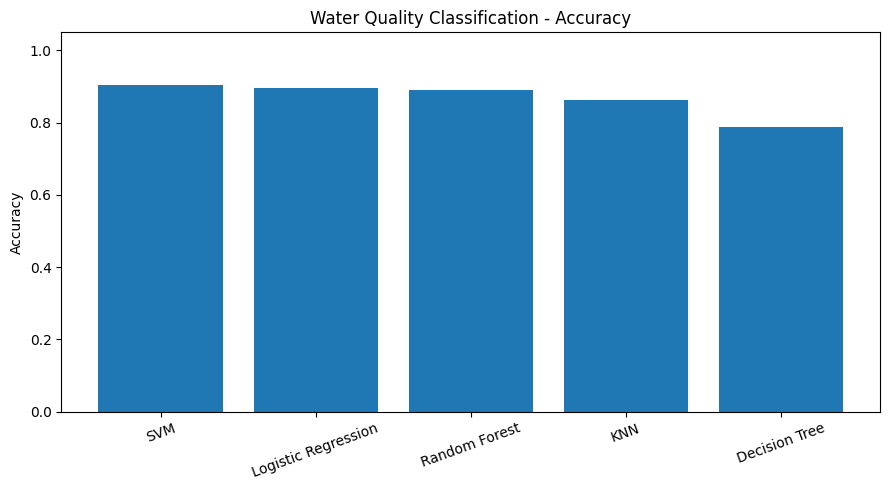

In [11]:
result_table = pd.DataFrame({
    "Algorithm": list(results.keys()),
    "Accuracy": list(results.values())
}).sort_values("Accuracy", ascending=False)

print(result_table)
plt.figure(figsize=(9, 5))
plt.bar(result_table["Algorithm"], result_table["Accuracy"])
plt.title("Water Quality Classification - Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 7. Classification report and confusion matrix

In [12]:
best_name = max(results, key=results.get)
best_model = models[best_name]
predictions = best_model.predict(X_test)

print("Best model:", best_name)
print(classification_report(y_test, predictions))
print("Confusion matrix:\\n", confusion_matrix(y_test, predictions))


Best model: SVM
              precision    recall  f1-score   support

        safe       0.89      0.93      0.91       120
      unsafe       0.92      0.88      0.90       120

    accuracy                           0.90       240
   macro avg       0.90      0.90      0.90       240
weighted avg       0.90      0.90      0.90       240

Confusion matrix:\n [[111   9]
 [ 14 106]]


## 8. Predict one sample
The following values are only an illustrative classroom example.

In [13]:
sample = pd.DataFrame([{
    "ph": 7.0,
    "hardness": 180,
    "solids": 15000,
    "chloramines": 7.0,
    "sulfate": 320,
    "conductivity": 400,
    "organic_carbon": 10.0,
    "trihalomethanes": 60,
    "turbidity": 3.2
}])

print("Predicted class:", best_model.predict(sample)[0])


Predicted class: safe


## 9. Conclusion

The project uses one dataset to train and compare KNN, Decision Tree, Logistic Regression, Random Forest, and SVM. The models classify samples into the dataset's two labels: safe and unsafe.

**Important:** This is only a machine-learning classroom exercise using synthetic data. It is not a certified water test, and it must not be used for drinking-water safety decisions. Real water requires laboratory testing against applicable standards.
